# Choosing the search settings, tested on my questions (KAN-221, first look for KAN-99)
Gözde Nur Özdemir · ELIZA · Sprint 2

**What this notebook does:** it tests the choices behind the search used in `src/embedding.ipynb` and writes the winners in `config/rag.yaml`. The embedding model itself is checked in `src/embedding.ipynb` (step 2). Every choice is either taken from a source or measured here.

| Step | Question | Where the choice comes from | Jira |
|---|---|---|---|
| 1 | Which questions, and how do we score? | instructor's slides: *"compute Recall@k / MRR on gold IDs"* | |
| 2 | Should words be removed at all? | Dickinson 2026, *Stop Removing Stopwords* | KAN-221 |
| 3 | How much do frequent words count in BM25? | the weights (IDF) of our BM25 library | KAN-221 |
| 4 | Which frequent words are useless? A jury of three LLMs | instructor's feedback; Verga et al. 2024, *Replacing Judges with Juries* | KAN-221 |
| 5 | Does removing them help? | Dickinson 2026: *"the burden of proof sits with removal"* | KAN-221 |
| 6 | Dense, BM25 or hybrid? And bge-base or bge-small? | design decisions D12 and D10 | KAN-99 (first look) |
| 7 | How many chunks (top-k)? | design decision D12 | KAN-99 (first look) |

**How every step works, in plain words:**
1. Write the rule first: what has to be better for a choice to win.
2. Measure every option on my questions with the same scores.
3. Keep the winner and write it in `config/rag.yaml`; if nothing wins, the default stays.

**The embedding model: what we expected and what we found**
1. **Sprint 1 (D10):** we chose bge-base on paper, because it is the larger model and was described as stronger on retrieval, and planned to check it with Recall@k in Sprint 2.
2. **`embedding.ipynb` step 2 (dense search only):** bge-small found more gold provisions (Recall@5 0.48 against 0.40); bge-base put the first correct chunk higher (MRR 0.53 against 0.26).
3. **Step 6 here (hybrid search, the one we use):** the same picture: bge-small Recall@5 0.52 against 0.48; bge-base MRR 0.64 against 0.45.
4. **Our rule, written before running:** Recall@5 decides (D10's measure), so bge-small replaces bge-base in `config/rag.yaml`.
5. **This is not what we expected,** but six questions are few: when the teammates have added their questions and the val split is ready (KAN-53), KAN-99 repeats the test on all the val questions, and if bge-base wins there, we switch back.

**What each step found** (details under each step):
| Step | Result | Written in `config/rag.yaml` |
|---|---|---|
| 2 | Removing words can change the meaning: 27 of 105 chunks contain "not", "no" or "nor" | nothing removed by default |
| 3 | Our BM25 does not push the most frequent words to 0: the 15 words in at least half of the chunks all get weight 0.89 | 20 candidates for step 4 |
| 4 | The jury marks 11 function words; in practice Qwen3 decided, because the other two models did not tell the words apart | |
| 5 | Removing the 11 words helps BM25 (Recall@5 0.25 → 0.33) | `bm25.remove: jury` |
| 6 | Hybrid beats dense and BM25 alone; inside hybrid, bge-small finds more gold provisions than bge-base (Recall@5 0.52 against 0.48) | `retrieval.mode: hybrid`, `embedding.model: bge-small` |
| 7 | 5 chunks find more than 3; 8 find nothing more | `retrieval.top_k: 5` |

**Questions used:** only my questions on Annex III 3(b), **B-01 to B-06**. The team's other questions are kept for the `val`/`test` split (KAN-53) and the full measurement in KAN-99.

## Summary
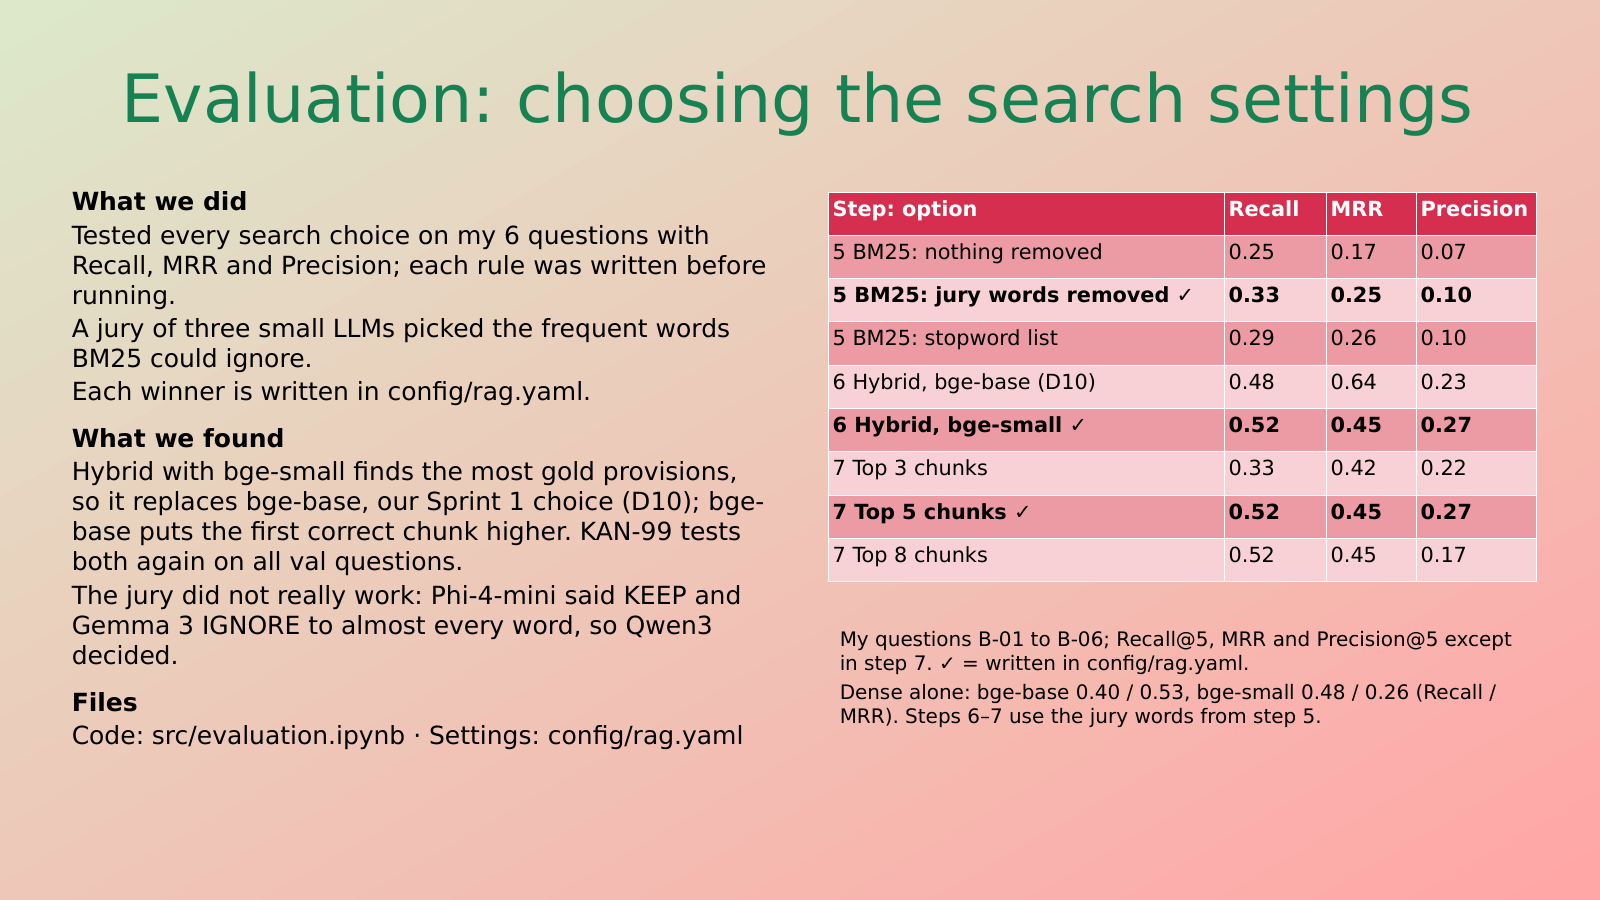

**Run in Google Colab:** [open this notebook in Colab](https://colab.research.google.com/github/ELIZA-DI502/ELIZA_DI502_ORGANIZATION/blob/KAN-221-stronger-models/src/evaluation.ipynb), choose *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. The first cell gets the repository and installs everything.

**Install once, in the terminal** (not in the notebook), in the same Python environment as Jupyter:
```
pip install sentence-transformers chromadb rank_bm25 pandas pyyaml requests scikit-learn umap-learn matplotlib
```

In [ ]:
# Only in Google Colab: get the repository and install what is needed (a few minutes the first time).
# On your own computer this cell does nothing.
import os, subprocess, sys, time
if "google.colab" in sys.modules:
    REPO = "/content/ELIZA_DI502_ORGANIZATION"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "-b", "KAN-221-stronger-models", "https://github.com/ELIZA-DI502/ELIZA_DI502_ORGANIZATION.git", REPO], check=True)
        subprocess.run("pip -q install sentence-transformers chromadb rank_bm25 umap-learn", shell=True, check=True)
    os.chdir(REPO + "/src")
    if subprocess.run("which ollama", shell=True, capture_output=True).returncode:      # install Ollama once
        subprocess.run("apt-get -qq install -y zstd > /dev/null; curl -fsSL https://ollama.com/install.sh | sh > /dev/null", shell=True, check=True)
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)
    import yaml
    for m in yaml.safe_load(open("../config/rag.yaml"))["judge"]["jury"]:
        print("Downloading", m); subprocess.run(["ollama", "pull", m], check=True, capture_output=True)


## 1. Which questions, and how do we score?
For each of B-01 to B-06 the team wrote the **gold source**: the provisions that answer it.
- **Recall@k:** share of the gold provisions in the top k chunks. A question with 4 gold provisions and 2 of them in the top 5 counts as 0.5, not as a success.
- **MRR:** 1 / rank of the first correct chunk (1.0 = always first).
- **Precision@k:** share of the top k chunks that are gold provisions; unrelated chunks lower it.

In [5]:
import csv, json, os, re
from collections import Counter
import numpy as np, pandas as pd, requests, yaml
pd.set_option("display.max_colwidth", None)
np.random.seed(42)

HOME = os.path.expanduser("~")
try:
    here = os.getcwd()
except OSError:                                     # the folder this notebook was started in was deleted or is blocked
    os.chdir(HOME)
    here = HOME

def readable(folder):
    """True if rag.yaml in this folder can be opened (macOS can block Downloads, Desktop and Documents)."""
    try:
        open(os.path.join(folder, "rag.yaml")).close()
        return True
    except OSError:
        return False

IN_REPO = os.path.exists("../config/rag.yaml")      # opened from src/ in the repository
places = [here] + [os.path.join(HOME, p, "ELIZA") for p in ["", "Downloads", "Desktop", "Documents"]]
FOLDER = next((f for f in places if readable(f)), None)
assert IN_REPO or FOLDER, f"rag.yaml not found or blocked. Move the ELIZA folder into your home folder: {HOME}"
print("Files read from:", "the repository" if IN_REPO else "the ELIZA folder")      # no personal path in the output
P = lambda path: path if IN_REPO else os.path.join(FOLDER, os.path.basename(path))
CONFIG = yaml.safe_load(open(P("../config/rag.yaml")))
chunks = [json.loads(line) for line in open(P("../data/chunks.jsonl"), encoding="utf-8")]
questions = {r["id"]: r for r in csv.DictReader(open(P("../docs/eval/eval-set-v1.csv"), encoding="utf-8-sig"))}
ref_of = {c["chunk_id"]: c["ref"] for c in chunks}
words = lambda text: re.findall(r"[a-z0-9]+", text.lower())
print(len(chunks), "chunks,", len(questions), "questions")
dev = [questions[q] for q in ["B-01", "B-02", "B-03", "B-04", "B-05", "B-06"]]

def score(search, k=5):
    """Recall@k, MRR and Precision@k over my questions B-01 to B-06."""
    recall, rr, precision = [], [], []
    for q in dev:
        gold = [g.strip() for g in q["gold_source"].split(";")]
        refs = [ref_of[c] for c in search(q["question"])[:k]]
        hit = lambda r: any(r.startswith(g) or g.startswith(r) for g in gold)
        recall.append(np.mean([any(r.startswith(g) or g.startswith(r) for r in refs) for g in gold]))
        rr.append(next((1 / n for n, r in enumerate(refs, 1) if hit(r)), 0))
        precision.append(np.mean([hit(r) for r in refs]))
    return {"Recall@5" if k == 5 else f"Recall@{k}": round(np.mean(recall), 2), "MRR": round(np.mean(rr), 2),
            "Precision@5" if k == 5 else f"Precision@{k}": round(np.mean(precision), 2)}

pd.DataFrame(dev)[["id", "question", "gold_source"]]

Files read from: the ELIZA folder
105 chunks, 26 questions


,id,question,gold_source
0,B-01,We made a tool that only takes the grades teachers already gave and calculates the weighted average. Is this still a high-risk AI system?,"Article 6(2); Article 6(3), first subparagraph; Article 6(3), second subparagraph, point (a); Article 6(3), third subparagraph"
1,B-02,Our AI only checks the exams that teachers have already written and points out typos and unclear questions. Is our product high-risk under the AI Act or not? Just tell us yes or no.,"Article 6(3), first subparagraph; Article 6(3), second subparagraph, point (b); Article 6(4); Article 49(2)"
2,B-03,"Okay, and if we decide our grade calculator is not high-risk, do we still have to do anything before we launch it?",Article 6(4); Article 49(2)
3,B-04,"Does the AI Act's prohibition on AI systems that infer emotions in education institutions apply to a webcam feature that detects whether students are bored or frustrated during an online lesson, and is there an exception?","Article 5(1), first subparagraph, point (f)"
4,B-05,As the product manager I need a checklist: which requirements does the AI Act set for a high-risk AI system that grades students' work?,Article 8(1); Article 9(1); Article 10(1); Article 11(1); Article 12(1); Article 13(1); Article 14(1); Article 15(1)
5,B-06,We plan to launch an AI tool that marks students' essays and gives each one a score. From what date do the AI Act's high-risk rules apply to a tool like this?,"Article 113, third paragraph, point (c)(i); Annex III, point 3(b)"


## 2. Should words be removed at all?
**Dense search (embedding)** reads the full `embed_text`: heading + the sentence before a point + the provision. The model reads normal sentences, and small words change a rule: *"shall **not** be considered to be high-risk"* means the opposite without "not".

**Keyword search (BM25)** reads the same text in lower case, split into words. We **do not remove stopwords by default**. A 2026 study on court decisions (Dickinson, *Stop Removing Stopwords*) found that the usual stopword lists (scikit-learn, NLTK, spaCy) made legal text classification slightly worse in all 12 tests, and that even word-by-word tuned lists gave no measurable gain. Its rule: *"the burden of proof sits with removal"*: a word is removed only if removing it is shown to help. Step 5 tests this, and on our questions removing the jury's words did help, so they are removed.

In [7]:
example = next(c for c in chunks if c["chunk_id"] == "ART6-3-1")
print("TEXT:", example["text"][:150], "...")
print("BM25:", words(example["text"])[:18], "...")
print(sum(any(w in {"not", "no", "nor"} for w in words(c["text"])) for c in chunks), "of 105 chunks contain a negation")

TEXT: 3. By derogation from paragraph 2, an AI system referred to in Annex III shall not be considered to be high-risk where it does not pose a significant  ...
BM25: ['3', 'by', 'derogation', 'from', 'paragraph', '2', 'an', 'ai', 'system', 'referred', 'to', 'in', 'annex', 'iii', 'shall', 'not', 'be', 'considered'] ...
27 of 105 chunks contain a negation


**Comment:** Nothing is removed yet: BM25 sees “by”, “from” and “an”, and also “not”. 27 of the 105 chunks contain a negation, so a careless stopword list could change the meaning of about a quarter of the provisions.

## 3. How much do frequent words count in BM25?
BM25 gives every word a weight (IDF): the rarer the word, the higher the weight. We show the weights of the BM25 library we use (`rank_bm25`, Okapi BM25). A word in only one chunk gets 4.24. A word in more than half of the chunks would get a weight below 0 in the Okapi formula, so the library gives all such words the same small weight instead: 0.25 × the average weight = 0.89.

The table shows the **20 most frequent words**, their weight, and how many chunks and questions contain them. These 20 are the candidates for step 4.

In [10]:
from rank_bm25 import BM25Okapi
bm25_all = BM25Okapi([words(c["embed_text"]) for c in chunks])      # BM25 with no word removed
in_q = Counter(w for q in questions.values() for w in set(words(q["question"])))
in_c = Counter(w for c in chunks for w in set(words(c["embed_text"])))

weights = pd.DataFrame([{"word": w, "% of chunks": round(100 * n / len(chunks)), "BM25 weight (IDF)": round(bm25_all.idf[w], 2),
                         "% of questions": round(100 * in_q[w] / len(questions))} for w, n in in_c.items()])
candidates = weights.sort_values("% of chunks", ascending=False).head(20).reset_index(drop=True)
print("Weight of a word in only one chunk:", round(max(bm25_all.idf.values()), 2))
candidates


Weight of a word in only one chunk: 4.24


,word,% of chunks,BM25 weight (IDF),% of questions
0,article,100,0.89,0
1,the,91,0.89,77
2,of,89,0.89,8
3,ai,86,0.89,73
4,in,76,0.89,23
5,to,74,0.89,62
6,shall,70,0.89,0
7,and,66,0.89,65
8,risk,65,0.89,46
9,paragraph,64,0.89,0


**Comment:** The 15 words in at least half of the chunks (“article”, “the”, “of”, “ai” …) all get the same weight, 0.89. That is more than the weight of “that” or “this” (0.13), although those are rarer. So in our BM25 the most frequent words are **not** pushed close to 0: “the” still adds to the score of almost every chunk, which is why removing words can help here (step 5). Some of these words are also in many questions (“ai” 73%, “risk” and “high” 46%), so frequency alone cannot decide what to drop.

## 4. A jury of three LLMs labels the candidates
The instructor asked us to let an LLM decide which frequent words are useless, with a **different model** than our answer model. Instead of one judge, we use a **jury of three models from different companies**, and the majority wins. Verga et al. (2024, *Replacing Judges with Juries*) showed that a panel of three models from different families agrees better with people than one large judge (Cohen's kappa 0.76 vs 0.63 for GPT-4 on Natural Questions), has less bias towards its own family, and is cheaper; for yes/no labels they use the majority vote.

| Model | Company | Why |
|---|---|---|
| `qwen3:14b` | Alibaba | Qwen3 worked with thinking turned off in our model selection spike |
| `phi4:14b` | Microsoft | the full Phi-4; Phi-4-mini is our fallback answer model (D9) |
| `gemma3:12b` | Google | a third family of about the same size |

**Why 12–14B models?** In the first run we used the 4B versions (`qwen3:4b`, `phi4-mini`, `gemma3:4b`): phi4-mini answered KEEP for all 20 words and gemma3:4b IGNORE for 18, so they did not tell the words apart and Qwen3 alone decided. The larger versions of the same three families are tried here; they need a GPU, so this step runs in Google Colab (free T4 GPU, link above).

None is **Llama** (our answer model, D9) or **Claude** (used to draft the questions). Same prompt, three examples of each word from our chunks, temperature 0 (in `config/rag.yaml`, `judge`). In Colab the first cell downloads them; on your own computer run `ollama pull` for each model first.

In [13]:
PROMPT = """This word appears in many EU AI Act provisions. Examples:
{examples}
Should a keyword search IGNORE it (common wording that does not help to find the right provision)
or KEEP it (a question can depend on it)? If in doubt, KEEP.
Answer in one line: IGNORE or KEEP, then a reason of at most 12 words.
WORD: {word}"""

installed = [m["name"] for m in requests.get(CONFIG["judge"]["url"].replace("/api/chat", "/api/tags")).json()["models"]]
missing = [m for m in CONFIG["judge"]["jury"] if not any(i.startswith(m) for i in installed)]
assert not missing, f"Run in the terminal first: {'  '.join('ollama pull ' + m for m in missing)}"

def ask(model, prompt):
    """The final answer of a model in Ollama, with the settings in config/rag.yaml; thinking off for Qwen3."""
    body = {"model": model, "stream": False, "messages": [{"role": "user", "content": prompt}],
            "options": {"temperature": CONFIG["judge"]["temperature"], "num_predict": CONFIG["judge"]["num_predict"]}}
    if model.startswith("qwen3"):
        body["think"] = False
        body["messages"][0]["content"] += " /no_think"         # Qwen3's own switch, also works with older Ollama
    answer = requests.post(CONFIG["judge"]["url"], json=body, timeout=300).json()
    if "error" in answer:
        raise RuntimeError(f"Ollama, {model}: {answer['error']}")
    text = answer["message"]["content"]
    if model.startswith("qwen3") and "</think>" not in text and text.lstrip().lower().startswith(("okay", "we are", "hmm")):
        return "UNCLEAR (thinking did not finish)"
    return text.split("</think>")[-1].strip()                  # keep only the final answer, after any thinking

def label(text):
    """IGNORE or KEEP if the final answer starts with it, otherwise UNCLEAR."""
    m = re.match(r"\W*(IGNORE|KEEP)\b", text.upper())
    return m[1] if m else "UNCLEAR"

def examples(word):
    return "\n".join([f'- {c["ref"]}: {c["text"][:150]}...' for c in chunks if word in words(c["text"])][:3])

jury = candidates[["word", "% of questions"]].copy()
for model in CONFIG["judge"]["jury"]:
    answers = []
    for n, w in enumerate(jury["word"], 1):
        answers.append(ask(model, PROMPT.format(examples=examples(w), word=w)))
        print(f"{model} {n}/{len(jury)}: {w} -> {answers[-1][:60]}")
    jury[model] = [label(a) for a in answers]
    jury[model + " reason"] = answers
models = CONFIG["judge"]["jury"]
jury["majority"] = np.where((jury[models] == "IGNORE").sum(axis=1) >= 2, "IGNORE", "KEEP")
JURY_IGNORE = set(jury.loc[jury["majority"] == "IGNORE", "word"])
print("The jury would ignore:", sorted(JURY_IGNORE))
print("Votes per model:", {m: jury[m].value_counts().to_dict() for m in models})
print("Models that gave the same label to every word (they do not tell words apart):",
      [m for m in models if jury[m].nunique() == 1] or "none")
jury[["word", "% of questions", *models, "majority"]]

qwen3:4b 1/20: article -> KEEP, standard legal term for provisions.
qwen3:4b 2/20: the -> IGNORE  
common stop word, no meaning for search
qwen3:4b 3/20: of -> IGNORE  
Common preposition, no specificity
qwen3:4b 4/20: ai -> KEEP, core term for AI systems in all provisions
qwen3:4b 5/20: in -> IGNORE  
common preposition in legal text
qwen3:4b 6/20: to -> IGNORE  
Common placeholder, no legal relevance in provision
qwen3:4b 7/20: shall -> IGNORE  
Common legal verb, not specific to provisions.
qwen3:4b 8/20: and -> IGNORE  
common conjunction, no specific meaning
qwen3:4b 9/20: risk -> KEEP, Central to high-risk AI classification
qwen3:4b 10/20: paragraph -> KEEP (Identifies numbered sections in AI Act provisions.)
qwen3:4b 11/20: high -> KEEP, high is essential for high-risk AI classification in E
qwen3:4b 12/20: systems -> KEEP, core term in AI Act scope definitions
qwen3:4b 13/20: system -> KEEP, Core term in AI Act definitions
qwen3:4b 14/20: or -> KEEP, or connects critical altern

,word,% of questions,qwen3:4b,phi4-mini,gemma3:4b,majority
0,article,0,KEEP,KEEP,IGNORE,KEEP
1,the,77,IGNORE,KEEP,IGNORE,IGNORE
2,of,8,IGNORE,KEEP,IGNORE,IGNORE
3,ai,73,KEEP,KEEP,IGNORE,KEEP
4,in,23,IGNORE,KEEP,IGNORE,IGNORE
5,to,62,IGNORE,KEEP,IGNORE,IGNORE
6,shall,0,IGNORE,KEEP,IGNORE,IGNORE
7,and,65,IGNORE,KEEP,IGNORE,IGNORE
8,risk,46,KEEP,KEEP,IGNORE,KEEP
9,paragraph,0,KEEP,KEEP,IGNORE,KEEP


**Comment:** The jury would ignore 11 function words (for example “the”, “of”, “and”, “shall”) and keeps the words our questions depend on, such as “ai”, “risk” and “high” (in 46–73% of the questions). But the jury did not work as planned: phi4-mini answered KEEP for all 20 words and gemma3 answered IGNORE for 18, so neither told the words apart, and the majority is always Qwen3’s vote. In practice the list comes from one model, so step 5 decides on measured scores, not on the jury alone.

## 5. Does removing words help? Tested on my questions
Following the *burden of proof* rule, we compare three versions of BM25 on my questions **B-01 to B-06** (Annex III 3(b), planned for the `val` split):
- **none:** nothing removed (the default)
- **jury:** the words the jury marked IGNORE are removed
- **stopwords:** the scikit-learn stopword list is removed, but "not", "no", "nor" are kept

Scores, as in the instructor's slides (*"compute Recall@k / MRR on gold IDs"*): **Recall@5** = share of the gold provisions in the top 5; **MRR** = 1 / rank of the first correct chunk; **Precision@5** = share of the top 5 chunks that are gold provisions. A question with 4 gold provisions and 2 of them in the top 5 counts as Recall 0.5, not as a success: partial hits are counted as partial, and the unrelated chunks lower Precision.

**Rule:** a version replaces "none" only if it is better on Recall@5 or MRR and worse on neither. Six questions are few (one question changes Recall@5 by about 0.17), so this is a first check; it is repeated on all the team's `val` questions in KAN-99.

In [16]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
REMOVE = {"none": set(), "jury": JURY_IGNORE, "stopwords": set(ENGLISH_STOP_WORDS) - {"not", "no", "nor"}}

def bm25_search(remove):
    index = BM25Okapi([[w for w in words(c["embed_text"]) if w not in remove] for c in chunks])
    return lambda q: [chunks[n]["chunk_id"] for n in np.argsort(-index.get_scores([w for w in words(q) if w not in remove]))]

test = pd.DataFrame([{"version": v, **score(bm25_search(words_out))} for v, words_out in REMOVE.items()]).set_index("version")
rule = ["Recall@5", "MRR"]                                   # the rule uses these two, as written above
better = lambda v: (test.loc[v, rule] >= test.loc["none", rule]).all() and (test.loc[v, rule] > test.loc["none", rule]).any()
CHOSEN = next((v for v in ["jury", "stopwords"] if better(v)), "none")
print("Chosen:", CHOSEN, "(write it in config/rag.yaml, bm25: remove)")
test

Chosen: jury (write it in config/rag.yaml, bm25: remove)


,Recall@5,MRR,Precision@5
version,,,
none,0.25,0.17,0.07
jury,0.33,0.25,0.10
stopwords,0.29,0.26,0.10


**Comment:** Removing the jury’s 11 words raised Recall@5 from 0.25 to 0.33 and MRR from 0.17 to 0.25, so by our rule BM25 now ignores them. The standard stopword list was close (0.29 and 0.26) but lower on Recall@5; with six questions this is a first check, repeated on the val split in KAN-99.

## 6. Dense, BM25 or hybrid? And which embedding model?
- **Dense (E1, the baseline):** the chunks closest to the question vector.
- **BM25:** keyword search with the words chosen in step 5.
- **Hybrid (E2):** both lists joined with Reciprocal Rank Fusion: each chunk gets `1 / (60 + rank)` from each list, and the two are added. 60 is the value from the RRF paper (Cormack et al., 2009).

**Which embedding model?** All the candidates in `config/rag.yaml` are compared **inside hybrid search**, the search we use: the three D10 options (MiniLM, bge-small, bge-base) and two larger models, `bge-large-en-v1.5` (the largest of the same family) and `mxbai-embed-large-v1` (another open model of the same size, which uses the same query instruction). All run on a CPU.

**Rule (written before running):** D10 says the model is *"checked with Recall@k"*, so the hybrid search with the higher **Recall@5** wins; if they are equal, the higher MRR wins. The winner goes into `config/rag.yaml` (`embedding.model`), and `embedding.ipynb` uses it.

In [19]:
from sentence_transformers import SentenceTransformer
R = CONFIG["retrieval"]
INSTRUCTION = CONFIG["embedding"]["query_instruction"]
keyword = lambda q: bm25_search(REMOVE[CHOSEN])(q)[:R["candidates"]]

def dense_with(name):
    """Dense search with one embedding model."""
    model = SentenceTransformer(name, device="cpu")
    vectors = model.encode([c["embed_text"] for c in chunks], normalize_embeddings=True)
    instruction = INSTRUCTION if any(k in name for k in ("bge", "mxbai")) else ""     # these models expect the query instruction
    return lambda q: [chunks[n]["chunk_id"] for n in np.argsort(-(vectors @ model.encode([instruction + q], normalize_embeddings=True)[0]))][:R["candidates"]]

def hybrid_of(dense):
    """The dense list and the BM25 list joined with RRF."""
    def search(question):
        rrf = Counter()
        for ranked in (dense(question), keyword(question)):
            for rank, cid in enumerate(ranked, 1):
                rrf[cid] += 1 / (R["rrf_k"] + rank)
        return [cid for cid, _ in rrf.most_common()]
    return search

rows, hybrids = [{"search": "BM25", **score(keyword)}], {}
short_name = lambda name: name.split("/")[1].replace("-en-v1.5", "").replace("-v1", "")
for name in CONFIG["embedding"]["candidates"]:
    short = short_name(name)
    dense = dense_with(name)
    hybrids[name] = hybrid_of(dense)
    rows += [{"search": f"dense, {short}", **score(dense)}, {"search": f"hybrid, {short}", **score(hybrids[name])}]

searches = pd.DataFrame(rows).set_index("search")
best = max(hybrids, key=lambda n: tuple(searches.loc["hybrid, " + short_name(n), ["Recall@5", "MRR"]]))
hybrid = hybrids[best]                                    # used in step 7
print("Winner by Recall@5 inside hybrid search (D10):", best, "-> write it in config/rag.yaml, embedding: model")
searches

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Winner by Recall@5 inside hybrid search (D10): BAAI/bge-small-en-v1.5 -> write it in config/rag.yaml, embedding: model


,Recall@5,MRR,Precision@5
search,,,
BM25,0.33,0.25,0.10
"dense, bge-base",0.40,0.53,0.17
"hybrid, bge-base",0.48,0.64,0.23
"dense, bge-small",0.48,0.26,0.23
"hybrid, bge-small",0.52,0.45,0.27


**Comment:** With both models, hybrid search is better than dense or BM25 alone, so `retrieval.mode` stays hybrid. In Sprint 1 (D10) we expected bge-base to be the stronger model, but on our questions hybrid search with bge-small found more gold provisions (Recall@5 0.52 against 0.48) and fewer unrelated chunks (Precision@5 0.27 against 0.23). bge-base still puts the first correct chunk higher (MRR 0.64 against 0.45). By the rule written above, bge-small replaces bge-base in `config/rag.yaml`. The difference is small with six questions, so KAN-99 tests both models again on all the team's val questions.

## 7. How many chunks should come back? (top-k)
Some of my questions need several provisions: B-05 needs eight Articles (8 to 15), but only 5 chunks come back, so it can never reach Recall 1. The design document (D12) plans to choose top-k from 3, 5 or 8. More chunks find more gold provisions but also bring more unrelated ones (lower Precision) and more text for the answer model to read.

In [22]:
topk = pd.DataFrame([{"top-k": k, **dict(zip(["Recall", "MRR", "Precision"], score(hybrid, k).values()))} for k in [3, 5, 8]])
topk

,top-k,Recall,MRR,Precision
0,3,0.33,0.42,0.22
1,5,0.52,0.45,0.27
2,8,0.52,0.45,0.17


**Comment:** With bge-small, 5 chunks find more gold provisions than 3 (Recall 0.52 against 0.33), and 8 chunks find nothing more but bring more unrelated chunks (Precision 0.27 → 0.17). So `top_k` stays 5; D12 confirms it on the val split in KAN-99.

## The decisions, written in `config/rag.yaml`
| Setting | Chosen | Step |
|---|---|---|
| `bm25.remove` | the LLM jury's 11 words | 5 |
| `retrieval.mode` | hybrid | 6 |
| `embedding.model` | `BAAI/bge-small-en-v1.5` (was bge-base in D10) | 6 |
| `retrieval.top_k` | 5 (confirmed on the val split in KAN-99, as D12 says) | 7 |

## Next: KAN-99
- Repeat steps 5–7 on all the team's `val` questions (after KAN-53) and log them in W&B; compare bge-small and bge-base again on all the val questions.
- The instructor's RAG metrics: Context Entities Recall (*"for fact-heavy text such as regulations"*) and, with the generated answers, Faithfulness.
- Questions that need several provisions (B-05; multi-hop questions like B-03 and B-06; the instructor's slides: *"the retriever has to find every document in the chain"*) can be Sprint 3 experiments: **query decomposition** (an LLM splits the question into one sub-question per provision) or **MMR** (Maximal Marginal Relevance, Carbonell & Goldstein 1998: the top chunks are chosen to be relevant **and** different from each other).